# AMI Meeting Dataset - Exploratory Data Analysis

## What are we doing?

In this notebook, we explore the AMI meeting dataset that we downloaded locally.

The main purpose is to understand what data we have before using it in our
speaker diarization and meeting-intelligence pipeline.

We will check:

- how many meetings are available
- how many speakers are present
- whether the required audio files exist
- how long the meeting recordings are
- whether any files or records are missing
- whether there are duplicate meeting records
- how much each speaker talks
- how much annotation data is available locally

The raw AMI audio and annotations stay on the local machine. Only the notebook
and generated summary statistics should be shared through GitHub.

### Importing the libraries

Before starting the analysis, we import the Python libraries that we will need throughout the notebook.

`json` is used to read the dataset manifest, while `re` and `ElementTree` help us work with the AMI annotation files. `Path` makes it easier to work with file locations, and `Counter` is useful for counting meetings and annotation files.

For the actual analysis, we use `pandas` to organize the data into tables, `matplotlib` to create graphs, and `soundfile` to read information such as the duration of the audio recordings.

In [17]:
from __future__ import annotations

import json
import re
import xml.etree.ElementTree as ET
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import soundfile as sf




### Setting up the file paths

Here, we set up the paths to the files and folders that will be used in the analysis.

Since the notebook can be opened either from the main project folder or from the `notebooks` folder, the first few lines automatically find the project root. This makes the notebook easier to run on different machines without manually changing paths.

We then define the locations of the dataset manifest, the AMI segment annotations, and the output summary file. Finally, we check that the manifest actually exists before continuing with the analysis.

In [18]:
# Resolve repo root from any folder inside the repo (repo root, notebooks/, notebooks/01_data/)
CWD = Path.cwd().resolve()
ROOT = next(p for p in [CWD, *CWD.parents] if (p / "data" / "manifests").exists())
MANIFEST_PATH = ROOT / "data" / "manifests" / "ami_sample.json"
SEGMENTS_DIR = ROOT / "data" / "raw" / "segments"
OUTPUT_SUMMARY = ROOT / "outputs" / "eda_ami_sample_summary.json"

print("ROOT:", ROOT)
print("Manifest:", MANIFEST_PATH)
assert MANIFEST_PATH.exists(), f"Missing manifest: {MANIFEST_PATH}"

ROOT: /Users/aashimataneja/Real-Time-Multi-Speaker-Meeting-Intelligence
Manifest: /Users/aashimataneja/Real-Time-Multi-Speaker-Meeting-Intelligence/data/manifests/ami_sample.json



### Loading the dataset manifest

Now we load the AMI manifest file and read the meeting information stored in it.

The manifest gives us a quick overview of the data being used in the project, such as the dataset name, sample ID, and the meetings included in the current sample.

We also display the meeting information as a table so it is easier to see the details of each meeting before starting the analysis.

In [19]:
manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))
meetings = manifest.get("meetings", [])

print("Dataset:", manifest.get("dataset"))
print("Sample ID:", manifest.get("sample_id"))
print("Meetings in manifest:", len(meetings))
pd.DataFrame(meetings)

Dataset: AMI
Sample ID: ami_sample_v1
Meetings in manifest: 1


,meeting_id,audio_path,reference_rttm,reference_transcript,num_speakers,notes
0,ES2002a,data/raw/ami/ES2002a/audio.wav,data/raw/ami/ES2002a/reference.rttm,data/raw/ami/ES2002a/transcript.txt,4,Paths are local-only; audio is not stored in t...


### Getting the audio duration

This function is used to find the length of an audio recording.

It first checks whether the audio file actually exists. If the file is available, we use `soundfile` to read its duration in seconds.

If the file is missing or cannot be read for some reason, the function returns `None` instead of stopping the entire notebook with an error.

In [20]:
def audio_duration_seconds(path: Path) -> float | None:
    if not path.exists():
        return None
    try:
        return float(sf.info(str(path)).duration)
    except Exception:
        return None



### Checking the meeting files and data quality

In this step, we go through each meeting in the manifest and check whether the data we need is actually available.

For each meeting, we check the meeting ID, look for duplicate records, verify the main audio file, and calculate its duration when possible. We also check whether the individual headset recordings and speaker segment annotation files are available.

Any problem we find, such as a missing audio file or duplicate meeting ID, is saved in a separate list instead of stopping the notebook.

At the end, we create two tables: one gives an overview of each meeting and its files, and the other shows any validation issues that were found.

In [21]:

rows = []
issues = []
seen_ids: set[str] = set()

for meeting in meetings:
    meeting_id = meeting.get("meeting_id")
    if not meeting_id:
        issues.append({"meeting_id": None, "issue": "missing meeting_id"})
        continue
    if meeting_id in seen_ids:
        issues.append({"meeting_id": meeting_id, "issue": "duplicate meeting_id in manifest"})
    seen_ids.add(meeting_id)

    audio_rel = meeting.get("audio_path")
    audio_path = ROOT / audio_rel if audio_rel else None
    duration = audio_duration_seconds(audio_path) if audio_path else None

    if audio_path is None:
        issues.append({"meeting_id": meeting_id, "issue": "missing audio_path field"})
    elif not audio_path.exists():
        issues.append({"meeting_id": meeting_id, "issue": f"missing audio file: {audio_rel}"})
    elif duration is None:
        issues.append({"meeting_id": meeting_id, "issue": f"unreadable audio file: {audio_rel}"})

    headset_paths = meeting.get("headset_paths") or []
    missing_headsets = [p for p in headset_paths if not (ROOT / p).exists()]
    for p in missing_headsets:
        issues.append({"meeting_id": meeting_id, "issue": f"missing headset file: {p}"})

    segment_paths = meeting.get("reference_segments") or []
    missing_segments = [p for p in segment_paths if not (ROOT / p).exists()]
    for p in missing_segments:
        issues.append({"meeting_id": meeting_id, "issue": f"missing segment file: {p}"})

    rows.append(
        {
            "meeting_id": meeting_id,
            "split": meeting.get("split"),
            "num_speakers_manifest": meeting.get("num_speakers"),
            "audio_path": audio_rel,
            "audio_exists": bool(audio_path and audio_path.exists()),
            "duration_sec": duration,
            "duration_min": None if duration is None else duration / 60.0,
            "n_headset_files": len(headset_paths),
            "n_missing_headsets": len(missing_headsets),
            "n_segment_files": len(segment_paths),
            "n_missing_segments": len(missing_segments),
        }
    )

meeting_df = pd.DataFrame(rows)
issues_df = pd.DataFrame(issues)

display(meeting_df)
print("\nValidation issues:", len(issues_df))
display(issues_df if not issues_df.empty else pd.DataFrame(columns=["meeting_id", "issue"]))

,meeting_id,split,num_speakers_manifest,audio_path,audio_exists,duration_sec,duration_min,n_headset_files,n_missing_headsets,n_segment_files,n_missing_segments
0,ES2002a,None,4,data/raw/ami/ES2002a/audio.wav,False,None,None,0,0,0,0



Validation issues: 1


,meeting_id,issue
0,ES2002a,missing audio file: data/raw/ami/ES2002a/audio...


### Creating a summary of the dataset

Now that we have checked the meeting files, we calculate a few overall statistics to get a quick picture of the dataset.

Here we find the number of unique meetings, total audio duration, average meeting length, and number of speakers in each meeting. We also include the number of validation issues found in the previous step.

Finally, we collect these values into one summary so the main dataset information can be viewed in one place and saved later.

In [22]:
n_meetings = meeting_df["meeting_id"].nunique()
total_duration_sec = meeting_df["duration_sec"].fillna(0).sum()
total_duration_min = total_duration_sec / 60.0
mean_duration_min = meeting_df["duration_min"].mean()
speakers_per_meeting = meeting_df[["meeting_id", "num_speakers_manifest"]].drop_duplicates()

summary = {
    "dataset": manifest.get("dataset"),
    "sample_id": manifest.get("sample_id"),
    "n_meetings": int(n_meetings),
    "n_manifest_rows": int(len(meeting_df)),
    "total_audio_duration_sec": round(float(total_duration_sec), 2),
    "total_audio_duration_min": round(float(total_duration_min), 2),
    "mean_meeting_duration_min": None
    if pd.isna(mean_duration_min)
    else round(float(mean_duration_min), 2),
    "speakers_per_meeting": speakers_per_meeting.set_index("meeting_id")[
        "num_speakers_manifest"
    ].to_dict(),
    "n_validation_issues": int(len(issues_df)),
}

print(json.dumps(summary, indent=2))

{
  "dataset": "AMI",
  "sample_id": "ami_sample_v1",
  "n_meetings": 1,
  "n_manifest_rows": 1,
  "total_audio_duration_sec": 0.0,
  "total_audio_duration_min": 0.0,
  "mean_meeting_duration_min": null,
  "speakers_per_meeting": {
    "ES2002a": 4
  },
  "n_validation_issues": 1
}


/var/folders/tq/h683bhx1777_7nr9hhxfgt3c0000gn/T/ipykernel_87556/3230527026.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  total_duration_sec = meeting_df["duration_sec"].fillna(0).sum()


### Visualizing meeting length and speaker count

To make the dataset easier to understand, we plot two simple graphs.

The first graph shows the length of each meeting in minutes. The second shows how many speakers are listed for each meeting in the manifest.

If the required information is missing, the notebook displays a message instead of creating an empty graph. These plots give us a quick visual overview of the meetings in the current dataset.

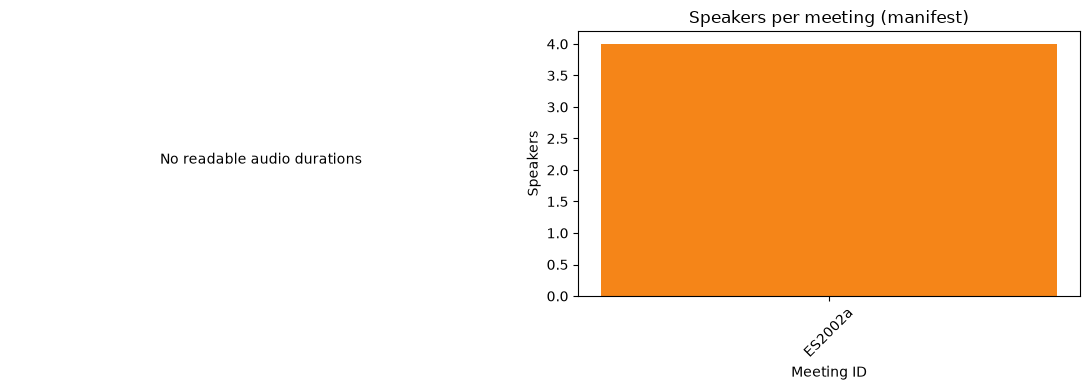

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

plot_df = meeting_df.dropna(subset=["duration_min"])
if not plot_df.empty:
    axes[0].bar(plot_df["meeting_id"], plot_df["duration_min"], color="#4C78A8")
    axes[0].set_title("Meeting length (minutes)")
    axes[0].set_xlabel("Meeting ID")
    axes[0].set_ylabel("Minutes")
    axes[0].tick_params(axis="x", rotation=45)
else:
    axes[0].text(0.5, 0.5, "No readable audio durations", ha="center")
    axes[0].set_axis_off()

spk = speakers_per_meeting.dropna()
if not spk.empty:
    axes[1].bar(spk["meeting_id"], spk["num_speakers_manifest"], color="#F58518")
    axes[1].set_title("Speakers per meeting (manifest)")
    axes[1].set_xlabel("Meeting ID")
    axes[1].set_ylabel("Speakers")
    axes[1].tick_params(axis="x", rotation=45)
else:
    axes[1].text(0.5, 0.5, "No speaker counts", ha="center")
    axes[1].set_axis_off()

plt.tight_layout()
plt.show()

### Reading the speaker segment annotations

The AMI dataset stores speaker timing information in XML files. Each file contains the speech segments for a particular speaker in a meeting.

This function reads one of those XML files, gets the meeting ID and speaker label from the filename, and then extracts the start and end time of each speech segment.

For every segment, we also calculate how long the speaker was talking. The results are returned as a table so we can use them later to analyze speaking time for each participant.

In [24]:
NITE_NS = {"nite": "http://nite.sourceforge.net/"}


def parse_segment_file(path: Path) -> pd.DataFrame:
    tree = ET.parse(path)
    root = tree.getroot()
    # Filename pattern: ES2002a.A.segments.xml
    match = re.match(r"^(?P<meeting>.+)\.(?P<speaker>[A-Z])\.segments\.xml$", path.name)
    meeting_id = match.group("meeting") if match else path.stem
    speaker = match.group("speaker") if match else "?"

    records = []
    for seg in root.findall("segment", NITE_NS) + root.findall("segment"):
        start = seg.attrib.get("transcriber_start")
        end = seg.attrib.get("transcriber_end")
        if start is None or end is None:
            continue
        start_f = float(start)
        end_f = float(end)
        records.append(
            {
                "meeting_id": meeting_id,
                "speaker": speaker,
                "start": start_f,
                "end": end_f,
                "duration": max(0.0, end_f - start_f),
            }
        )
    return pd.DataFrame(records)



### Loading the speaker segment data

Now we collect the speaker segment annotations for each meeting.

For every meeting, we first check whether the manifest already provides the annotation file paths. If not, we search the local `segments` folder for matching files. Each available file is then read using the function from the previous step.

Finally, we combine all of the speaker segments into one table. This gives us a single place to view the meeting ID, speaker, start time, end time, and duration of each speech segment.

In [25]:
segment_frames = []
for meeting in meetings:
    meeting_id = meeting["meeting_id"]
    paths = meeting.get("reference_segments") or []
    if paths:
        candidate_paths = [ROOT / p for p in paths]
    else:
        candidate_paths = sorted(SEGMENTS_DIR.glob(f"{meeting_id}.*.segments.xml"))

    for path in candidate_paths:
        if path.exists():
            segment_frames.append(parse_segment_file(path))
        else:
            print(f"Missing segment file: {path}")

segments_df = pd.concat(segment_frames, ignore_index=True) if segment_frames else pd.DataFrame(
    columns=["meeting_id", "speaker", "start", "end", "duration"]
)

print("Segment rows:", len(segments_df))
display(segments_df.head(10))


Segment rows: 554


,meeting_id,speaker,start,end,duration
0,ES2002a,A,77.408,80.955,3.547
1,ES2002a,A,132.380,142.056,9.676
2,ES2002a,A,237.359,239.245,1.886
3,ES2002a,A,265.659,267.435,1.776
4,ES2002a,A,275.672,276.227,0.555
5,ES2002a,A,280.439,282.696,2.257
6,ES2002a,A,290.031,291.400,1.369
7,ES2002a,A,293.138,294.656,1.518
8,ES2002a,A,309.360,311.028,1.668
9,ES2002a,A,311.996,312.950,0.954


### Comparing speaking time for each speaker

Now that we have the speaker segments, we use them to see how much each person spoke during the meeting.

For each speaker, we count the number of speech segments and add up their total speaking time. We also convert the speaking time from seconds to minutes so it is easier to understand.

Finally, we display the results in a table and a bar chart, which makes it easy to compare the speaking time of different speakers.

,meeting_id,speaker,n_segments,speech_sec,speech_min
0,ES2002a,A,68,194.006,3.233433
1,ES2002a,B,218,980.884,16.348067
2,ES2002a,C,38,89.016,1.483600
3,ES2002a,D,230,773.000,12.883333


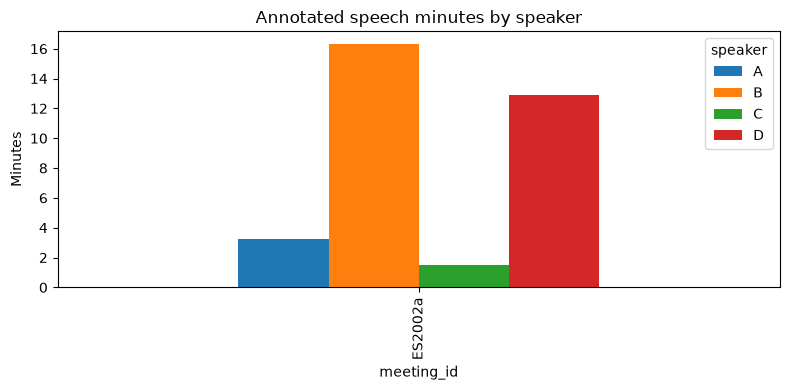

In [26]:
if not segments_df.empty:
    by_speaker = (
        segments_df.groupby(["meeting_id", "speaker"], as_index=False)
        .agg(n_segments=("duration", "count"), speech_sec=("duration", "sum"))
        .assign(speech_min=lambda d: d["speech_sec"] / 60.0)
    )
    display(by_speaker)

    pivot = by_speaker.pivot(index="meeting_id", columns="speaker", values="speech_min").fillna(0)
    pivot.plot(kind="bar", figsize=(8, 4), title="Annotated speech minutes by speaker")
    plt.ylabel("Minutes")
    plt.tight_layout()
    plt.show()
else:
    print("No segment annotations loaded. Download AMI manual annotations into data/raw/.")

### Checking the available annotation coverage

The AMI annotation download contains segment files for many meetings, not just the meeting currently listed in our manifest.

Here, we scan the local `segments` folder and count how many meetings have annotation files available. We also count how many speaker files are available for each meeting.

Finally, we plot the speaker-file counts to get a quick idea of how complete the local annotations are across the dataset.

Local segment meetings: 171
Local segment XML files: 687


,meeting_id,n_speaker_files
0,EN2001a,5
1,EN2001b,4
2,EN2001d,5
3,EN2001e,5
4,EN2002a,4
5,EN2002b,4
6,EN2002c,4
7,EN2002d,4
8,EN2003a,4
9,EN2004a,4


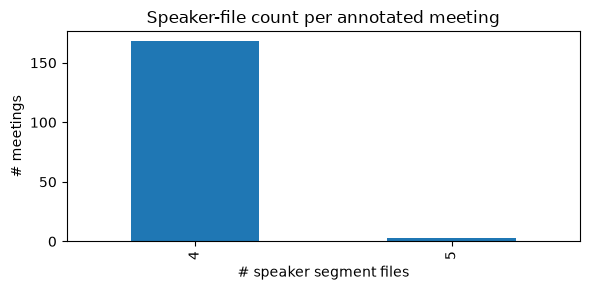

In [27]:
if SEGMENTS_DIR.exists():
    segment_files = sorted(SEGMENTS_DIR.glob("*.segments.xml"))
    meeting_ids = []
    for path in segment_files:
        match = re.match(r"^(?P<meeting>.+)\.[A-Z]\.segments\.xml$", path.name)
        if match:
            meeting_ids.append(match.group("meeting"))
    coverage = Counter(meeting_ids)
    coverage_df = (
        pd.DataFrame({"meeting_id": list(coverage.keys()), "n_speaker_files": list(coverage.values())})
        .sort_values("meeting_id")
        .reset_index(drop=True)
    )
    print("Local segment meetings:", coverage_df["meeting_id"].nunique())
    print("Local segment XML files:", len(segment_files))
    display(coverage_df.head(20))

    # How many speakers files per meeting (expect ~4 for scenario meetings)
    coverage_df["n_speaker_files"].value_counts().sort_index().plot(
        kind="bar", figsize=(6, 3), title="Speaker-file count per annotated meeting"
    )
    plt.xlabel("# speaker segment files")
    plt.ylabel("# meetings")
    plt.tight_layout()
    plt.show()
else:
    print("No local segments directory found.")

### Saving the EDA results

Finally, we save the main results from the analysis into a JSON summary file.

The summary includes the overall dataset statistics, any validation issues we found, meeting-level information, and the total speaking time for each speaker when segment annotations are available.

This gives us a small, shareable record of the EDA results without including any of the raw AMI audio files. The raw WAV files remain stored only on the local machine.

In [28]:
OUTPUT_SUMMARY.parent.mkdir(parents=True, exist_ok=True)

export = {
    **summary,
    "validation_issues": issues_df.to_dict(orient="records"),
    "meetings": meeting_df.to_dict(orient="records"),
}

if not segments_df.empty:
    export["segment_speech_minutes_by_speaker"] = (
        segments_df.groupby(["meeting_id", "speaker"])["duration"].sum()
        .div(60.0)
        .round(3)
        .reset_index(name="speech_min")
        .to_dict(orient="records")
    )

OUTPUT_SUMMARY.write_text(json.dumps(export, indent=2), encoding="utf-8")
print("Wrote", OUTPUT_SUMMARY)
print("Safe to share this summary JSON + notebook. Do not share raw wav files.")

Wrote /Users/aashimataneja/Real-Time-Multi-Speaker-Meeting-Intelligence/outputs/eda_ami_sample_summary.json
Safe to share this summary JSON + notebook. Do not share raw wav files.


## Notes and limitations

There are a few things to keep in mind when looking at the results from this notebook:

- For Part A, we are currently working with the `ES2002a` meeting in the project manifest. The downloaded AMI annotations contain information for many more meetings, but those meetings are not yet part of the current sample manifest.

- The expected number of speakers comes from the JSON manifest. The speaker labels found in the AMI segment XML files give us another way to check the speaker information using the actual annotations.

- The current manifest still contains a placeholder path for the meeting audio. Because of this, the notebook may report the audio as missing or show the duration as zero even though the AMI audio has been downloaded locally.

- This notebook focuses only on the AMI dataset. NOTSOFAR-1 and QMSum are not included in this EDA.

- As more meeting audio is added to the project manifest, we can run the same notebook again to update the statistics and visualizations.